# EXP-002：Jitter 單位修正

> 實驗紀錄與結論：[EXP-002-jitter-unit.md](EXP-002-jitter-unit.md)

**背景：** 排序時會加入隨機擾動（jitter），讓公平值相近的人隨機輪替，避免每天都是同一批人站同樣的班。

**問題：** 舊版把 jitter（0.3）直接加在公平值（節 ÷ 上班天）上。公平值的分母會隨月份累積，
因此同樣的 0.3，在月底代表的「節數差距」會被放大。

**改進：** 改以「節」為單位加入擾動，再除以上班天數，使擾動代表的節數不隨月份改變。

## 重現方式

```bash
npm run experiment -- scripts/experiments/exp-002-jitter-unit.ts    # 產生 data/exp-002/
.venv/Scripts/jupyter nbconvert --to notebook --execute --inplace docs/experiments/EXP-002-jitter-unit.ipynb
```

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from nbutils import BLUE, INK, MUTED, ORANGE, VIOLET, YELLOW, assert_close, load, mean_ci, mw, settle_all

variants = load("exp-002", "variants")
persons = load("exp-002", "persons")
runs = load("exp-002", "runs")

ORDER = ["ratio0.3", "shift1.0", "shift0.5", "shift0.2"]
COLOR = {"ratio0.3": ORANGE, "shift1.0": VIOLET, "shift0.5": BLUE, "shift0.2": YELLOW}
LABEL = {"ratio0.3": "Old: 0.3 in ratio units", "shift1.0": "1.0 shift", "shift0.5": "0.5 shift (current)",
         "shift0.2": "0.2 shift"}
SCEN = sorted(runs.scenario.unique(), key=lambda s: int(s[1:]))
print(f"persons: {len(persons):,} rows, runs: {len(runs)}, seeds: {runs.seed.nunique()}")
variants

persons: 26,760 rows, runs: 960, seeds: 30


,variant,name,jitter_unit,jitter
0,ratio0.3,舊版（公平值單位 0.3）,ratio,0.3
1,shift1.0,1.0 節,shift,1.0
2,shift0.5,0.5 節（現行）,shift,0.5
3,shift0.2,0.2 節,shift,0.2


## 1. 問題在哪裡：擾動被月份放大

jitter 會讓「公平值差距小於擾動幅度」的人被視為差不多，隨機排序。把擾動換算成節數：

- **舊版：** 公平值單位 0.3 → 相當於 0.3 × 上班天數 節。上班 20 天時，差 6 節的人仍可能被視為差不多。
- **新版：** 0.5 節，不隨月份改變。

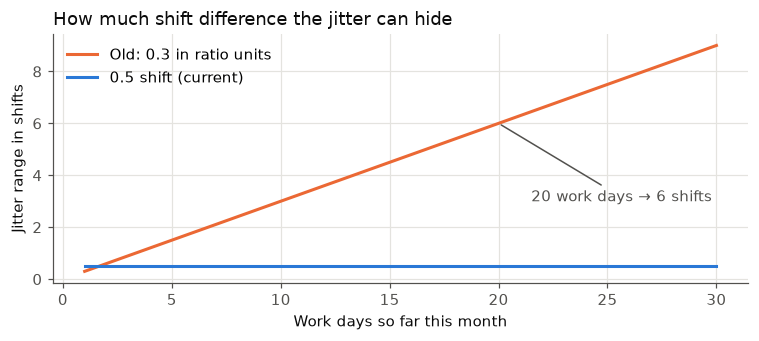

In [2]:
d = np.arange(1, 31)
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(d, 0.3 * d, color=ORANGE, lw=2, label=LABEL["ratio0.3"])
ax.plot(d, np.full_like(d, 0.5, dtype=float), color=BLUE, lw=2, label=LABEL["shift0.5"])
ax.annotate("20 work days → 6 shifts", xy=(20, 6), xytext=(21.5, 3), color=MUTED,
            arrowprops={"arrowstyle": "-", "color": MUTED})
ax.set_xlabel("Work days so far this month")
ax.set_ylabel("Jitter range in shifts")
ax.set_title("How much shift difference the jitter can hide")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

## 2. 硬性規定與交叉驗證

In [3]:
assert runs.violations.sum() == 0, "發現違規！"
print("✓ 違規數：0")
py = settle_all(persons, ["scenario", "variant", "seed"])
both = runs.merge(py, on=["scenario", "variant", "seed"])
assert_close(both.ts_rms, both.rms, "月結算偏差 RMS")
assert_close(both.ts_max_dev, both.max_dev, "最大偏差")

✓ 違規數：0


✓ 月結算偏差 RMS：與 TypeScript 結果一致（最大差異 5.0e-12）
✓ 最大偏差：與 TypeScript 結果一致（最大差異 5.0e-12）


## 3. 月結算偏差

點為 30 seeds 的平均，線段為 95% confidence interval。

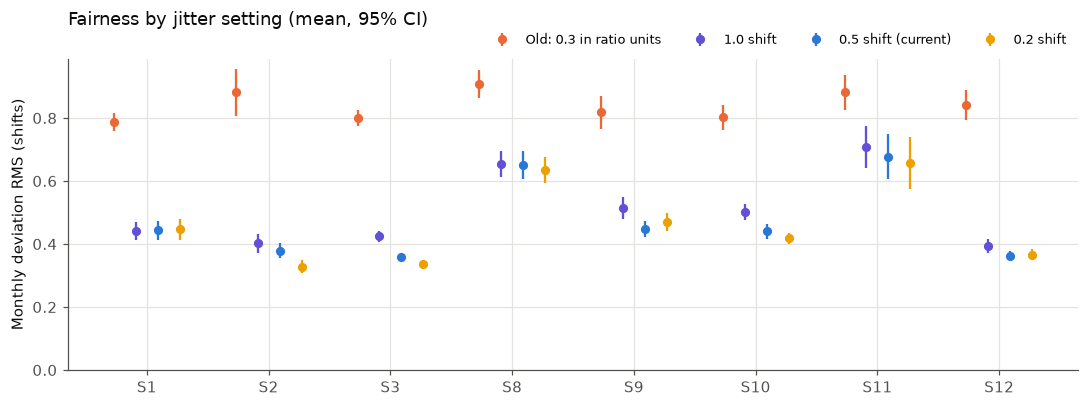

In [4]:
fig, ax = plt.subplots(figsize=(10, 3.8))
w = 0.18
for k, v in enumerate(ORDER):
    g = py[py.variant == v].groupby("scenario").rms
    m = g.mean().reindex(SCEN)
    se = g.agg(lambda x: 1.96 * x.std(ddof=1) / np.sqrt(len(x))).reindex(SCEN)
    x = np.arange(len(SCEN)) + (k - 1.5) * w
    ax.errorbar(x, m, yerr=se, fmt="o", ms=5, color=COLOR[v], capsize=0, lw=1.5, label=LABEL[v])
ax.set_xticks(range(len(SCEN)), SCEN)
ax.set_ylim(0, None)
ax.set_ylabel("Monthly deviation RMS (shifts)")
ax.set_title("Fairness by jitter setting (mean, 95% CI)", pad=22)
ax.legend(loc="lower right", bbox_to_anchor=(1, 1.0), ncol=4, fontsize=8.5)
plt.tight_layout()
plt.show()

In [5]:
rows = []
for sc in SCEN:
    g = {v: py[(py.scenario == sc) & (py.variant == v)].sort_values("seed") for v in ORDER}
    rows.append({"scenario": sc, **{f"RMS {v}": g[v].rms.mean() for v in ORDER},
                 "p old vs 0.5": mw(g["ratio0.3"].rms, g["shift0.5"].rms)[1],
                 "p 0.5 vs 0.2": mw(g["shift0.5"].rms, g["shift0.2"].rms)[1]})
tbl = pd.DataFrame(rows).set_index("scenario")
tbl.style.format("{:.2f}").format({"p old vs 0.5": "{:.1e}", "p 0.5 vs 0.2": "{:.3f}"})

,RMS ratio0.3,RMS shift1.0,RMS shift0.5,RMS shift0.2,p old vs 0.5,p 0.5 vs 0.2
scenario,,,,,,
S1,0.786470,0.441674,0.443567,0.446911,2.9e-11,0.918
S2,0.881159,0.401905,0.378989,0.327884,2.9e-11,0.005
S3,0.799476,0.424171,0.357671,0.335451,2.9e-11,0.019
S8,0.907640,0.654763,0.651314,0.635362,8.1e-09,0.636
S9,0.817859,0.513358,0.448734,0.470381,3.2e-11,0.240
S10,0.803186,0.501247,0.439939,0.418132,2.9e-11,0.249
S11,0.882306,0.706984,0.677076,0.657146,1.0e-04,0.549
S12,0.842023,0.394380,0.363471,0.365597,2.2e-11,0.913


- **舊版 vs 0.5 節：** 所有情境都顯著改善。
- **0.5 節 vs 0.2 節：** 多數情境沒有顯著差異；但 S2、S3 中 **0.2 節顯著較公平**（偏差較小）。

## 4. 原本選 0.5 而非 0.2 的理由：保留隨機輪替？

EXP-002 原本認為 0.2 節的擾動太小、排序太固定，會讓同一個人每天站相同的班。這裡用 **同班次重複率** 檢驗：

> 連續兩天都有站哨的人中，隔天被排到相同班次（或班次重疊）的比例。

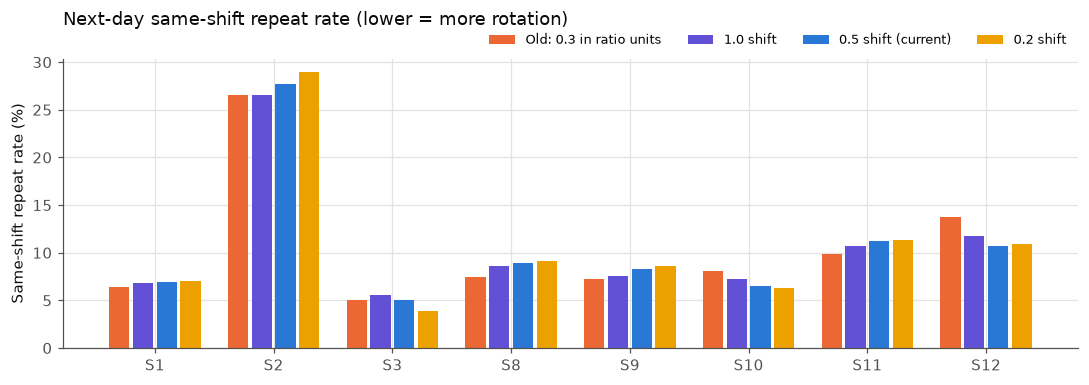

variant,ratio0.3,shift1.0,shift0.5,shift0.2,p 0.5 vs 0.2
scenario,,,,,
S1,6.4,6.9,7.0,7.1,0.631
S2,26.6,26.6,27.7,28.9,0.112
S3,5.1,5.5,5.0,3.9,0.003
S8,7.4,8.6,8.9,9.2,0.734
S9,7.3,7.5,8.3,8.6,0.515
S10,8.1,7.2,6.5,6.3,0.544
S11,9.9,10.7,11.2,11.3,0.853
S12,13.8,11.7,10.7,10.9,0.959


In [6]:
runs["repeat_rate"] = runs.repeat_same / runs.repeat_pairs
rep = runs.groupby(["scenario", "variant"]).apply(
    lambda g: g.repeat_same.sum() / g.repeat_pairs.sum(), include_groups=False).unstack()[ORDER].reindex(SCEN)

fig, ax = plt.subplots(figsize=(10, 3.6))
w = 0.2
for k, v in enumerate(ORDER):
    ax.bar(np.arange(len(SCEN)) + (k - 1.5) * w, rep[v] * 100, width=w - 0.03, color=COLOR[v], label=LABEL[v])
ax.set_xticks(range(len(SCEN)), SCEN)
ax.set_ylabel("Same-shift repeat rate (%)")
ax.set_title("Next-day same-shift repeat rate (lower = more rotation)", pad=22)
ax.legend(loc="lower right", bbox_to_anchor=(1, 1.0), ncol=4, fontsize=8.5)
plt.tight_layout()
plt.show()

p = {sc: mw(runs[(runs.scenario == sc) & (runs.variant == "shift0.5")].repeat_rate,
            runs[(runs.scenario == sc) & (runs.variant == "shift0.2")].repeat_rate)[1] for sc in SCEN}
(rep * 100).round(1).assign(**{"p 0.5 vs 0.2": pd.Series(p).round(3)})

## 結論

- **主要結論成立：** 改以「節」為單位後，月結算偏差從約 0.8～0.9 節降到約 0.35～0.7 節，所有情境 p < 0.001。
- **0.2、0.5、1.0 節的公平性相近**，但 0.2 節在 S2、S3 顯著略好（S2：0.33 vs 0.38 節）。
- **「0.5 節保留較多輪替」的理由不被數據支持：** 各版本的同班次重複率只差 1～2 個百分點，方向也不一致；
  唯一顯著的 S3 反而是 0.2 節輪替較多。重複率主要由人數決定（S2 只有 12 人，排法本來就很受限）。
- **🔍 待決定：** 數據傾向 0.2 節（公平性相同或略好、輪替沒有變差）。是否調整尚未決定，改動前應以新的實驗確認。